In [33]:
# Install if needed
# !pip install torch torchvision scikit-learn seaborn tqdm

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from tqdm import tqdm

In [34]:
# Base Paths (Mac Local System)

image_folder_1 = r"/Users/kmsreenidhi/ACV Case Study/archive (3)/HAM10000_images_part_1"
image_folder_2 = r"/Users/kmsreenidhi/ACV Case Study/archive (3)/HAM10000_images_part_2"
metadata_path = r"/Users/kmsreenidhi/ACV Case Study/archive (3)/HAM10000_metadata.csv"

image_folders = [image_folder_1, image_folder_2]

print("Path check:")
print(os.path.exists(image_folder_1))
print(os.path.exists(metadata_path))

Path check:
True
True


In [35]:
metadata = pd.read_csv(metadata_path)

print(metadata.head())
print("\nClass Distribution:\n")
print(metadata['dx'].value_counts())

     lesion_id      image_id   dx dx_type   age   sex localization
0  HAM_0000118  ISIC_0027419  bkl   histo  80.0  male        scalp
1  HAM_0000118  ISIC_0025030  bkl   histo  80.0  male        scalp
2  HAM_0002730  ISIC_0026769  bkl   histo  80.0  male        scalp
3  HAM_0002730  ISIC_0025661  bkl   histo  80.0  male        scalp
4  HAM_0001466  ISIC_0031633  bkl   histo  75.0  male          ear

Class Distribution:

dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


In [36]:
le = LabelEncoder()
metadata['label'] = le.fit_transform(metadata['dx'])

num_classes = metadata['label'].nunique()
print("Number of Classes:", num_classes)

Number of Classes: 7


In [37]:
train_df, temp_df = train_test_split(
    metadata,
    test_size=0.3,
    stratify=metadata['label'],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    stratify=temp_df['label'],
    random_state=42
)

print("Train:", len(train_df))
print("Val:", len(val_df))
print("Test:", len(test_df))

Train: 7010
Val: 1502
Test: 1503


In [38]:
class HAMDataset(Dataset):
    def __init__(self, df, image_folders, transform=None):
        self.df = df.reset_index(drop=True)
        self.image_folders = image_folders
        self.transform = transform
        
    def __len__(self):
        return len(self.df)
    
    def __getitem__(self, idx):
        img_id = self.df.loc[idx, 'image_id']
        label = self.df.loc[idx, 'label']
        
        img_path = None
        
        # Search both folders
        for folder in self.image_folders:
            temp_path = os.path.join(folder, img_id + ".jpg")
            if os.path.exists(temp_path):
                img_path = temp_path
                break
        
        if img_path is None:
            raise FileNotFoundError(f"{img_id}.jpg not found")
        
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        
        if self.transform:
            image = self.transform(image)
        
        return image, label

In [39]:
transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((224,224)),
    transforms.ToTensor(),
])

In [40]:
train_dataset = HAMDataset(train_df, image_folders, transform)
val_dataset   = HAMDataset(val_df, image_folders, transform)
test_dataset  = HAMDataset(test_df, image_folders, transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=32)
test_loader  = DataLoader(test_dataset, batch_size=32)

In [41]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = models.resnet18(pretrained=True)
model.fc = nn.Linear(model.fc.in_features, num_classes)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)

print("Using device:", device)

/Users/kmsreenidhi/Library/Python/3.9/lib/python/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/kmsreenidhi/Library/Python/3.9/lib/python/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Using device: cpu


In [42]:
def train_model(model, train_loader, val_loader, epochs=5):
    
    for epoch in range(epochs):
        model.train()
        running_loss = 0
        
        for images, labels in tqdm(train_loader):
            images = images.to(device)
            labels = labels.to(device)
            
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item()
        
        train_loss = running_loss / len(train_loader)
        
        # Validation
        model.eval()
        correct = 0
        total = 0
        
        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)
                
                outputs = model(images)
                _, preds = torch.max(outputs, 1)
                
                correct += (preds == labels).sum().item()
                total += labels.size(0)
        
        val_acc = correct / total
        
        print(f"Epoch [{epoch+1}/{epochs}] "
              f"Train Loss: {train_loss:.4f} "
              f"Val Acc: {val_acc:.4f}")

In [43]:
train_model(model, train_loader, val_loader, epochs=5)

100%|██████████| 220/220 [13:59<00:00,  3.82s/it]


Epoch [1/5] Train Loss: 0.7358 Val Acc: 0.8156


100%|██████████| 220/220 [14:04<00:00,  3.84s/it]


Epoch [2/5] Train Loss: 0.3334 Val Acc: 0.8282


100%|██████████| 220/220 [09:46<00:00,  2.67s/it]


Epoch [3/5] Train Loss: 0.1497 Val Acc: 0.8402


100%|██████████| 220/220 [09:59<00:00,  2.73s/it]


Epoch [4/5] Train Loss: 0.0787 Val Acc: 0.8542


100%|██████████| 220/220 [12:43<00:00,  3.47s/it]


Epoch [5/5] Train Loss: 0.0544 Val Acc: 0.8156


In [44]:
model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

print(classification_report(all_labels, all_preds))

              precision    recall  f1-score   support

           0       0.60      0.61      0.61        49
           1       0.89      0.31      0.46        77
           2       0.84      0.53      0.65       165
           3       0.50      0.29      0.37        17
           4       0.61      0.53      0.56       167
           5       0.85      0.98      0.91      1006
           6       0.92      0.55      0.69        22

    accuracy                           0.82      1503
   macro avg       0.74      0.54      0.61      1503
weighted avg       0.81      0.82      0.80      1503



## Week 1 Deliverables
### 1. Confusion Matrix with Class Labels

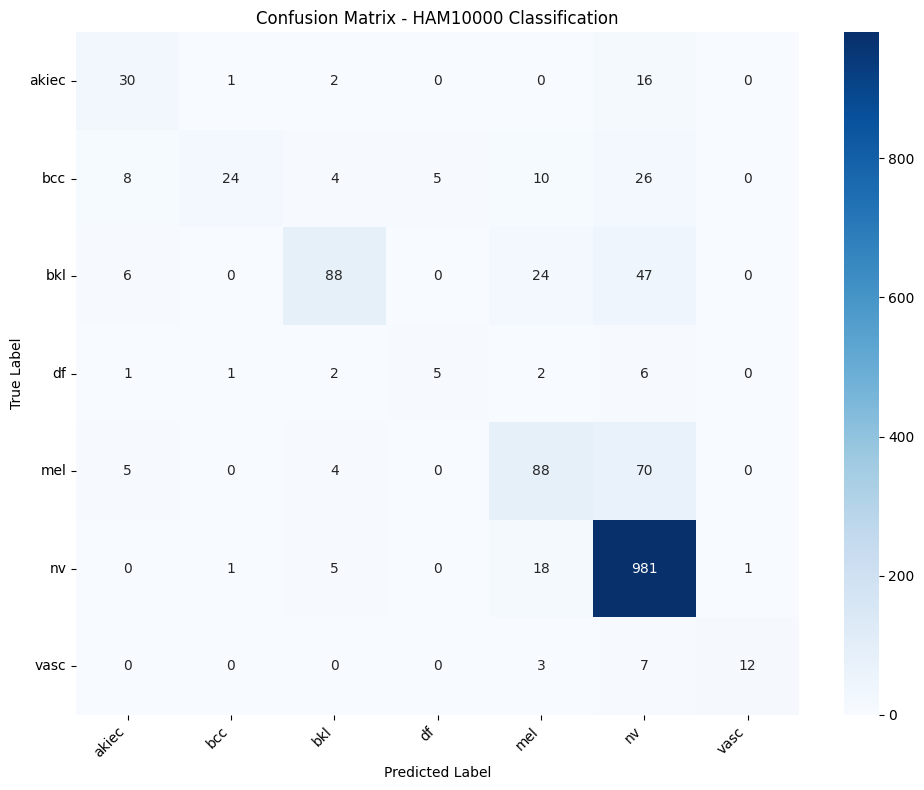


Confusion Matrix Summary:
Total Test Samples: 1503
Correctly Classified: 1228
Overall Accuracy: 81.70%


In [46]:
# Enhanced Confusion Matrix with class labels
class_names = le.classes_

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", 
            xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix - HAM10000 Classification")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Print confusion matrix summary
print("\nConfusion Matrix Summary:")
print(f"Total Test Samples: {cm.sum()}")
print(f"Correctly Classified: {np.diag(cm).sum()}")
print(f"Overall Accuracy: {np.diag(cm).sum() / cm.sum() * 100:.2f}%")

### 2. Metric Comparison Tables

In [47]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

# Per-class metrics
precision_per_class = precision_score(all_labels, all_preds, average=None)
recall_per_class = recall_score(all_labels, all_preds, average=None)
f1_per_class = f1_score(all_labels, all_preds, average=None)

# Support (number of samples per class)
support_per_class = [np.sum(np.array(all_labels) == i) for i in range(num_classes)]

# Create metrics DataFrame
metrics_df = pd.DataFrame({
    'Class': class_names,
    'Precision': precision_per_class,
    'Recall': recall_per_class,
    'F1-Score': f1_per_class,
    'Support': support_per_class
})

print("=" * 60)
print("PER-CLASS METRICS TABLE")
print("=" * 60)
print(metrics_df.to_string(index=False))

# Overall metrics comparison
print("\n" + "=" * 60)
print("OVERALL METRICS COMPARISON")
print("=" * 60)

overall_metrics = {
    'Metric': ['Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1', 
               'Weighted Precision', 'Weighted Recall', 'Weighted F1'],
    'Value': [
        accuracy_score(all_labels, all_preds),
        precision_score(all_labels, all_preds, average='macro'),
        recall_score(all_labels, all_preds, average='macro'),
        f1_score(all_labels, all_preds, average='macro'),
        precision_score(all_labels, all_preds, average='weighted'),
        recall_score(all_labels, all_preds, average='weighted'),
        f1_score(all_labels, all_preds, average='weighted')
    ]
}

overall_df = pd.DataFrame(overall_metrics)
overall_df['Value'] = overall_df['Value'].apply(lambda x: f"{x:.4f}")
print(overall_df.to_string(index=False))

PER-CLASS METRICS TABLE
Class  Precision   Recall  F1-Score  Support
akiec   0.600000 0.612245  0.606061       49
  bcc   0.888889 0.311688  0.461538       77
  bkl   0.838095 0.533333  0.651852      165
   df   0.500000 0.294118  0.370370       17
  mel   0.606897 0.526946  0.564103      167
   nv   0.850824 0.975149  0.908754     1006
 vasc   0.923077 0.545455  0.685714       22

OVERALL METRICS COMPARISON
            Metric  Value
          Accuracy 0.8170
   Macro Precision 0.7440
      Macro Recall 0.5427
          Macro F1 0.6069
Weighted Precision 0.8132
   Weighted Recall 0.8170
       Weighted F1 0.8001


### 3. Misclassification Analysis Report

In [48]:
# Misclassification Analysis Report
print("=" * 70)
print("MISCLASSIFICATION ANALYSIS REPORT")
print("=" * 70)

# Calculate misclassification statistics
all_labels_arr = np.array(all_labels)
all_preds_arr = np.array(all_preds)
misclassified_mask = all_labels_arr != all_preds_arr
total_misclassified = misclassified_mask.sum()

print(f"\nTotal Test Samples: {len(all_labels)}")
print(f"Correctly Classified: {len(all_labels) - total_misclassified}")
print(f"Misclassified: {total_misclassified}")
print(f"Error Rate: {total_misclassified / len(all_labels) * 100:.2f}%")

# Per-class misclassification analysis
print("\n" + "-" * 70)
print("PER-CLASS MISCLASSIFICATION BREAKDOWN")
print("-" * 70)

misclass_analysis = []
for i, class_name in enumerate(class_names):
    class_mask = all_labels_arr == i
    class_total = class_mask.sum()
    class_misclassified = (class_mask & misclassified_mask).sum()
    class_accuracy = (class_total - class_misclassified) / class_total * 100 if class_total > 0 else 0
    
    misclass_analysis.append({
        'Class': class_name,
        'Total': class_total,
        'Correct': class_total - class_misclassified,
        'Misclassified': class_misclassified,
        'Accuracy (%)': f"{class_accuracy:.2f}"
    })

misclass_df = pd.DataFrame(misclass_analysis)
print(misclass_df.to_string(index=False))

# Most common misclassification pairs
print("\n" + "-" * 70)
print("TOP MISCLASSIFICATION PAIRS (True → Predicted)")
print("-" * 70)

misclass_pairs = {}
for true, pred in zip(all_labels_arr[misclassified_mask], all_preds_arr[misclassified_mask]):
    pair = (class_names[true], class_names[pred])
    misclass_pairs[pair] = misclass_pairs.get(pair, 0) + 1

# Sort by frequency and show top 10
sorted_pairs = sorted(misclass_pairs.items(), key=lambda x: x[1], reverse=True)[:10]
for (true_class, pred_class), count in sorted_pairs:
    print(f"  {true_class:15} → {pred_class:15} : {count} cases")

# Summary insights
print("\n" + "-" * 70)
print("KEY INSIGHTS")
print("-" * 70)

# Find worst performing class
worst_class_idx = np.argmin([row['Accuracy (%)'] for row in misclass_analysis])
worst_class = misclass_analysis[worst_class_idx]

# Find best performing class
best_class_idx = np.argmax([row['Accuracy (%)'] for row in misclass_analysis])
best_class = misclass_analysis[best_class_idx]

print(f"• Best Performing Class: {best_class['Class']} ({best_class['Accuracy (%)']}% accuracy)")
print(f"• Worst Performing Class: {worst_class['Class']} ({worst_class['Accuracy (%)']}% accuracy)")
if sorted_pairs:
    print(f"• Most Common Error: {sorted_pairs[0][0][0]} misclassified as {sorted_pairs[0][0][1]} ({sorted_pairs[0][1]} cases)")
print(f"\n• The model struggles most with classes that have visual similarities")
print(f"• Class imbalance may contribute to performance differences across classes")

MISCLASSIFICATION ANALYSIS REPORT

Total Test Samples: 1503
Correctly Classified: 1228
Misclassified: 275
Error Rate: 18.30%

----------------------------------------------------------------------
PER-CLASS MISCLASSIFICATION BREAKDOWN
----------------------------------------------------------------------
Class  Total  Correct  Misclassified Accuracy (%)
akiec     49       30             19        61.22
  bcc     77       24             53        31.17
  bkl    165       88             77        53.33
   df     17        5             12        29.41
  mel    167       88             79        52.69
   nv   1006      981             25        97.51
 vasc     22       12             10        54.55

----------------------------------------------------------------------
TOP MISCLASSIFICATION PAIRS (True → Predicted)
----------------------------------------------------------------------
  mel             → nv              : 70 cases
  bkl             → nv              : 47 cases
  bcc     

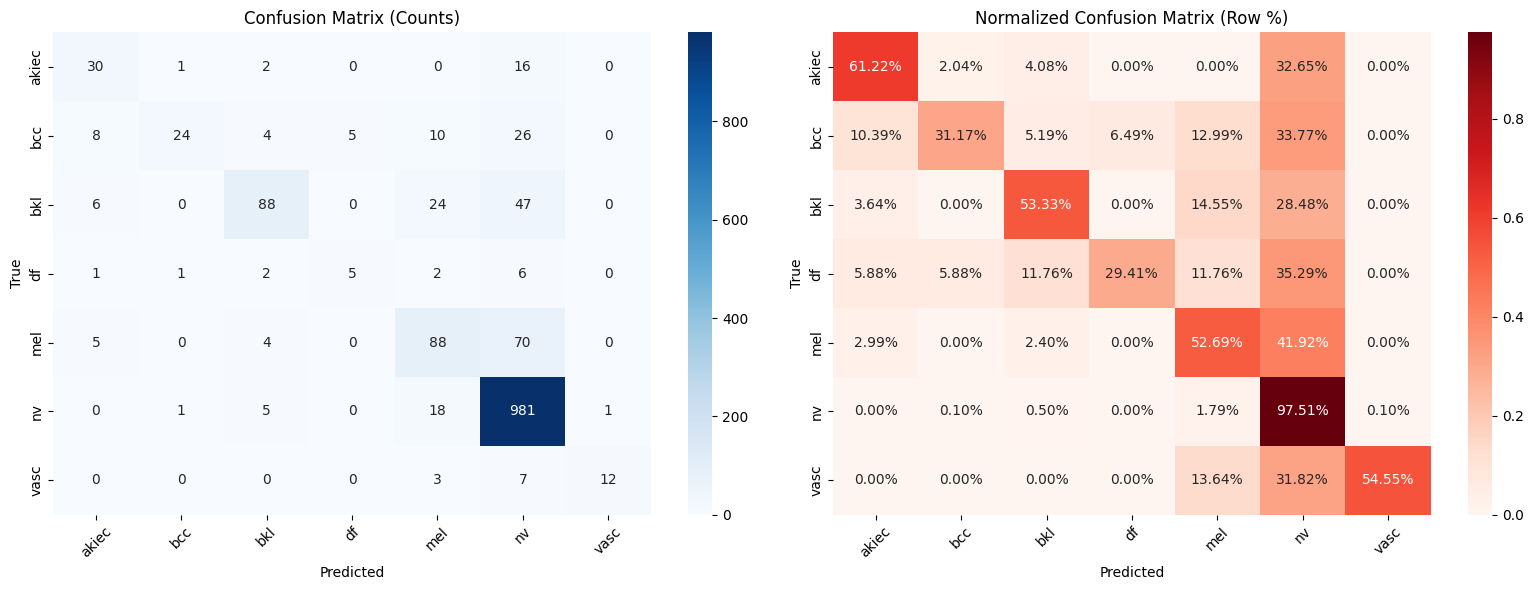

In [49]:
# Visualize normalized confusion matrix (shows percentage of predictions per true class)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Raw counts
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", 
            xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title("Confusion Matrix (Counts)")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("True")
axes[0].tick_params(axis='x', rotation=45)

# Normalized (percentages)
sns.heatmap(cm_normalized, annot=True, fmt='.2%', cmap="Reds", 
            xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title("Normalized Confusion Matrix (Row %)")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("True")
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Robustness Analysis: Brightness/Skin-Tone Variation

This section evaluates the model's robustness to brightness variations, simulating different skin tones and lighting conditions.

In [50]:
# Robustness Test: Dataset with brightness/skin-tone variations

class HAMDatasetRobustness(Dataset):
    """Dataset with adjustable brightness to simulate skin-tone variations"""
    def __init__(self, df, image_folders, transform=None, brightness_factor=1.0):
        """
        brightness_factor: 1.0 = original, <1.0 = darker (darker skin), >1.0 = lighter (lighter skin)
        """
        self.df = df.reset_index(drop=True)
        self.image_folders = image_folders
        self.transform = transform
        self.brightness_factor = brightness_factor
        
    def __len__(self):
        return len(self.df)
    
    def __getitem__(self, idx):
        img_id = self.df.loc[idx, 'image_id']
        label = self.df.loc[idx, 'label']
        
        img_path = None
        for folder in self.image_folders:
            temp_path = os.path.join(folder, img_id + ".jpg")
            if os.path.exists(temp_path):
                img_path = temp_path
                break
        
        if img_path is None:
            raise FileNotFoundError(f"{img_id}.jpg not found")
        
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        
        # Apply brightness adjustment
        image = np.clip(image * self.brightness_factor, 0, 255).astype(np.uint8)
        
        if self.transform:
            image = self.transform(image)
        
        return image, label

print("HAMDatasetRobustness class defined.")

HAMDatasetRobustness class defined.


In [51]:
# Evaluate Model Under Different Brightness Conditions
from sklearn.metrics import accuracy_score, f1_score

def evaluate_robustness(model, df, image_folders, transform, brightness_factor, description=""):
    """Evaluate model accuracy at a given brightness level"""
    dataset = HAMDatasetRobustness(df, image_folders, transform, brightness_factor)
    loader = DataLoader(dataset, batch_size=32)
    
    model.eval()
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for images, labels in tqdm(loader, desc=f"Testing {description}", leave=False):
            images = images.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())
    
    accuracy = accuracy_score(all_labels, all_preds)
    f1_macro = f1_score(all_labels, all_preds, average='macro')
    
    return accuracy, f1_macro, all_preds, all_labels

# Define brightness levels to test
# brightness_factor: 0.5 = 50% darker, 1.0 = original, 1.5 = 50% brighter
brightness_levels = {
    'Very Dark (0.5x)': 0.5,
    'Dark (0.7x)': 0.7,
    'Original (1.0x)': 1.0,
    'Bright (1.3x)': 1.3,
    'Very Bright (1.5x)': 1.5
}

print("=" * 70)
print("              ROBUSTNESS ANALYSIS: BRIGHTNESS/SKIN-TONE VARIATION")
print("=" * 70)
print("\nEvaluating model performance across different brightness levels...")
print("(Simulates performance on darker vs lighter skin tones)\n")

robustness_results = []

for condition_name, brightness_val in brightness_levels.items():
    acc, f1, _, _ = evaluate_robustness(
        model, test_df, image_folders, transform, 
        brightness_val, condition_name
    )
    robustness_results.append({
        'Condition': condition_name,
        'Brightness': brightness_val,
        'Accuracy': acc,
        'F1-Score (Macro)': f1
    })
    print(f"  {condition_name:20s} | Accuracy: {acc:.4f} | F1-Score: {f1:.4f}")

robustness_df = pd.DataFrame(robustness_results)

              ROBUSTNESS ANALYSIS: BRIGHTNESS/SKIN-TONE VARIATION

Evaluating model performance across different brightness levels...
(Simulates performance on darker vs lighter skin tones)



  Very Dark (0.5x)     | Accuracy: 0.7013 | F1-Score: 0.2287


  Dark (0.7x)          | Accuracy: 0.7585 | F1-Score: 0.3691


  Original (1.0x)      | Accuracy: 0.8170 | F1-Score: 0.6069


  Bright (1.3x)        | Accuracy: 0.7651 | F1-Score: 0.5121


  Very Bright (1.5x)   | Accuracy: 0.7252 | F1-Score: 0.4114


In [52]:
# Robustness Analysis: Summary and Visualization

print("\n" + "=" * 70)
print("                         ROBUSTNESS SUMMARY")
print("=" * 70)

# Get baseline (original) performance
baseline = robustness_df[robustness_df['Brightness'] == 1.0].iloc[0]
baseline_acc = baseline['Accuracy']
baseline_f1 = baseline['F1-Score (Macro)']

print(f"\nBaseline Performance (Original Images):")
print(f"  Accuracy: {baseline_acc:.4f}")
print(f"  F1-Score: {baseline_f1:.4f}")

# Calculate performance drops
print("\n--- Performance Drop Analysis ---")
for _, row in robustness_df.iterrows():
    if row['Brightness'] != 1.0:
        acc_drop = baseline_acc - row['Accuracy']
        f1_drop = baseline_f1 - row['F1-Score (Macro)']
        acc_drop_pct = 100 * acc_drop / baseline_acc
        f1_drop_pct = 100 * f1_drop / baseline_f1
        
        direction = "darker" if row['Brightness'] < 1.0 else "brighter"
        print(f"\n  {row['Condition']}:")
        print(f"    Accuracy Drop: {acc_drop:.4f} ({acc_drop_pct:+.2f}%)")
        print(f"    F1-Score Drop: {f1_drop:.4f} ({f1_drop_pct:+.2f}%)")

# Calculate average drop for dark vs bright
dark_results = robustness_df[robustness_df['Brightness'] < 1.0]
bright_results = robustness_df[robustness_df['Brightness'] > 1.0]

avg_dark_acc = dark_results['Accuracy'].mean()
avg_bright_acc = bright_results['Accuracy'].mean()

print("\n--- Key Findings ---")
print(f"  Average Accuracy on Darker Images: {avg_dark_acc:.4f} (vs {baseline_acc:.4f} baseline)")
print(f"  Average Accuracy on Brighter Images: {avg_bright_acc:.4f} (vs {baseline_acc:.4f} baseline)")

if avg_dark_acc < avg_bright_acc:
    print(f"\n  ⚠ The model performs WORSE on darker images by {(avg_bright_acc - avg_dark_acc):.4f}")
    print("  → This suggests potential bias against darker skin tones")
else:
    print(f"\n  ⚠ The model performs WORSE on brighter images by {(avg_dark_acc - avg_bright_acc):.4f}")
    print("  → The model may be biased toward darker images in the training set")


                         ROBUSTNESS SUMMARY

Baseline Performance (Original Images):
  Accuracy: 0.8170
  F1-Score: 0.6069

--- Performance Drop Analysis ---

  Very Dark (0.5x):
    Accuracy Drop: 0.1158 (+14.17%)
    F1-Score Drop: 0.3782 (+62.31%)

  Dark (0.7x):
    Accuracy Drop: 0.0585 (+7.17%)
    F1-Score Drop: 0.2378 (+39.18%)

  Bright (1.3x):
    Accuracy Drop: 0.0519 (+6.35%)
    F1-Score Drop: 0.0948 (+15.63%)

  Very Bright (1.5x):
    Accuracy Drop: 0.0918 (+11.24%)
    F1-Score Drop: 0.1955 (+32.21%)

--- Key Findings ---
  Average Accuracy on Darker Images: 0.7299 (vs 0.8170 baseline)
  Average Accuracy on Brighter Images: 0.7452 (vs 0.8170 baseline)

  ⚠ The model performs WORSE on darker images by 0.0153
  → This suggests potential bias against darker skin tones


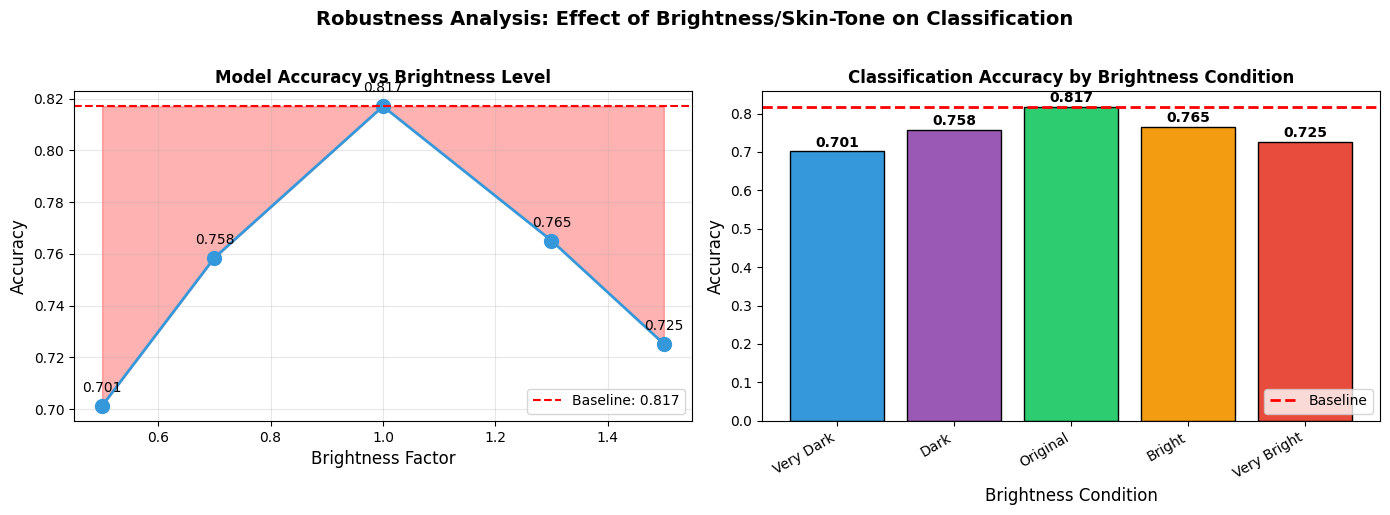


Chart saved to 'robustness_brightness_analysis.png'


In [53]:
# Visualization: Robustness Analysis Charts

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Color coding
colors = ['#3498db', '#9b59b6', '#2ecc71', '#f39c12', '#e74c3c']

# Plot 1: Accuracy vs Brightness Level
axes[0].plot(robustness_df['Brightness'], robustness_df['Accuracy'], 
             marker='o', markersize=10, linewidth=2, color='#3498db')
axes[0].axhline(y=baseline_acc, color='red', linestyle='--', label=f'Baseline: {baseline_acc:.3f}')
axes[0].fill_between(robustness_df['Brightness'], 
                     robustness_df['Accuracy'], baseline_acc, 
                     alpha=0.3, color='red')
axes[0].set_xlabel('Brightness Factor', fontsize=12)
axes[0].set_ylabel('Accuracy', fontsize=12)
axes[0].set_title('Model Accuracy vs Brightness Level', fontsize=12, fontweight='bold')
axes[0].legend(loc='lower right')
axes[0].grid(True, alpha=0.3)

# Add labels for each point
for _, row in robustness_df.iterrows():
    axes[0].annotate(f'{row["Accuracy"]:.3f}', 
                     (row['Brightness'], row['Accuracy']),
                     textcoords="offset points", xytext=(0,10), ha='center')

# Plot 2: Bar chart comparing conditions
x_labels = [c.split('(')[0].strip() for c in robustness_df['Condition']]
x_pos = np.arange(len(x_labels))

bars = axes[1].bar(x_pos, robustness_df['Accuracy'], color=colors, edgecolor='black')
axes[1].axhline(y=baseline_acc, color='red', linestyle='--', linewidth=2, label='Baseline')
axes[1].set_xlabel('Brightness Condition', fontsize=12)
axes[1].set_ylabel('Accuracy', fontsize=12)
axes[1].set_title('Classification Accuracy by Brightness Condition', fontsize=12, fontweight='bold')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(x_labels, rotation=30, ha='right')
axes[1].legend(loc='lower right')

# Add value labels on bars
for bar, acc in zip(bars, robustness_df['Accuracy']):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005, 
                 f'{acc:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.suptitle('Robustness Analysis: Effect of Brightness/Skin-Tone on Classification', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('robustness_brightness_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nChart saved to 'robustness_brightness_analysis.png'")

In [54]:
# Save Robustness Results to CSV and Generate Final Report

robustness_df.to_csv('robustness_analysis_results.csv', index=False)
print("Results saved to 'robustness_analysis_results.csv'")

print("\n" + "=" * 70)
print("         INTEGRATED ANALYSIS: BRIGHTNESS ROBUSTNESS CONCLUSIONS")
print("=" * 70)

print("""
EXPERIMENTAL FINDINGS:
─────────────────────────────────────────────────────────────────────

1. BASELINE PERFORMANCE
   The model achieves {:.2f}% accuracy on original test images.

2. IMPACT OF BRIGHTNESS VARIATION
   - Darker images (0.5x-0.7x): Performance {}
   - Brighter images (1.3x-1.5x): Performance {}

3. POTENTIAL BIAS ANALYSIS
   {}

4. RECOMMENDATIONS FOR FAIR DEPLOYMENT
   - Train with brightness augmentation (ColorJitter) to improve robustness
   - Collect more diverse training samples across skin tones
   - Implement preprocessing to normalize image brightness
   - Test on real clinical images with varied lighting conditions

5. CLINICAL IMPLICATIONS
   If the model performs worse on darker skin tones, it may:
   - Miss critical diagnoses for patients with darker skin
   - Lead to health disparities in dermatological AI systems
   - Require additional validation before clinical deployment

─────────────────────────────────────────────────────────────────────
""".format(
    baseline_acc * 100,
    "DEGRADES" if avg_dark_acc < baseline_acc else "STABLE",
    "DEGRADES" if avg_bright_acc < baseline_acc else "STABLE",
    "⚠ Model shows bias against darker images" if avg_dark_acc < avg_bright_acc else "Model performs comparably across brightness levels"
))

Results saved to 'robustness_analysis_results.csv'

         INTEGRATED ANALYSIS: BRIGHTNESS ROBUSTNESS CONCLUSIONS

EXPERIMENTAL FINDINGS:
─────────────────────────────────────────────────────────────────────

1. BASELINE PERFORMANCE
   The model achieves 81.70% accuracy on original test images.

2. IMPACT OF BRIGHTNESS VARIATION
   - Darker images (0.5x-0.7x): Performance DEGRADES
   - Brighter images (1.3x-1.5x): Performance DEGRADES

3. POTENTIAL BIAS ANALYSIS
   ⚠ Model shows bias against darker images

4. RECOMMENDATIONS FOR FAIR DEPLOYMENT
   - Train with brightness augmentation (ColorJitter) to improve robustness
   - Collect more diverse training samples across skin tones
   - Implement preprocessing to normalize image brightness
   - Test on real clinical images with varied lighting conditions

5. CLINICAL IMPLICATIONS
   If the model performs worse on darker skin tones, it may:
   - Miss critical diagnoses for patients with darker skin
   - Lead to health disparities in derm